# Import the data

Import library

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Import data

In [1]:
import sys
from pathlib import Path

# If your file is inside a subfolder named 'src'
sys.path.append(str(Path.cwd() / '..'))

import data

listings = data.load("listings")
print(f"{len(listings):,} sales, {listings['date_sold'].min():%B %Y} to {listings['date_sold'].max():%B %Y}")
listings.head()

/home/indy/.cache/huggingface/hub/datasets--Baliyang--SSU_data_dash/snapshots/96a258439e2a85f650699be8339e52d8ac5614b7/listings.parquet
150,000 sales, January 2021 to May 2026


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,...,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,...,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,...,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,...,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,...,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [10]:
off_market = data.load("off_market")
list_aware = data.load("list_aware")
print(f"{len(off_market):,} homes to value with no list price (off-market)")
print(f"{len(list_aware):,} homes to value that have a list price (list-aware)")
off_market.head()

3,974 homes to value with no list price (off-market)
4,064 homes to value that have a list price (list-aware)


,ml_num,date_listed,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,remarks
0,SYN-0011818,2026-05-04,Condo Apt,Apartment,1,1,0,0.0,300-499,NaN,NaN,North York,Hawthornbourne,43.594328,-79.416373,"Located on Elm Crescent, this one-bedroom apar..."
1,SYN-0117584,2026-08-15,Semi-Detached,2-Storey,3,2,2,1.0,1555,21.23,140.10,Scarborough,Spruceview,43.590486,-79.315004,Magnolia Ave in Spruceview – a solid semi with...
2,SYN-0065643,2026-05-05,Condo Apt,Apartment,1,1,1,0.0,685,NaN,NaN,Toronto,Sprucehaven,43.604231,-79.368203,Looking for more space in a condo? This 685 sq...
3,SYN-0031502,2026-09-04,Condo Apt,Apartment,2,1,0,0.0,500-699,NaN,NaN,Toronto,Cypressdale,43.720574,-79.388083,If you're a small family looking for a smart s...
4,SYN-0003276,2026-06-05,Detached,2-Storey,5,5,2,2.0,2844,65.17,129.14,Scarborough,Rowangardens,43.688588,-79.437290,Experience life on Spruce Crescent in Rowangar...


## Data exploration

From the quickstart

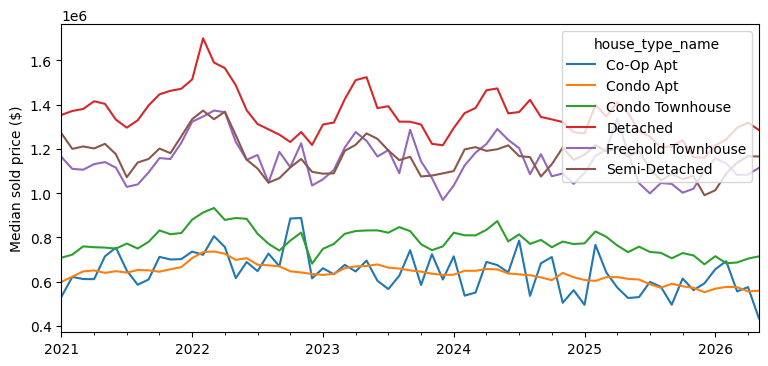

In [2]:
# A first look: the median sold price each month, by property type.
monthly = listings.groupby([listings["date_sold"].dt.to_period("M"), "house_type_name"])["sold_price"].median()
monthly.unstack().plot(figsize=(9, 4), ylabel="Median sold price ($)", xlabel="");

## Indy's exploration

In [3]:
print(listings.columns)

Index(['ml_num', 'sold_price', 'list_price', 'date_listed', 'date_sold',
       'days_on_market', 'house_type_name', 'house_style', 'bedrooms',
       'washrooms', 'parking_total', 'garage', 'house_area', 'lot_front',
       'lot_depth', 'municipality', 'community', 'latitude', 'longitude',
       'external_avm_estimate', 'external_avm_estimate_date', 'remarks'],
      dtype='object')


<Axes: xlabel='days_on_market', ylabel='sold_price'>

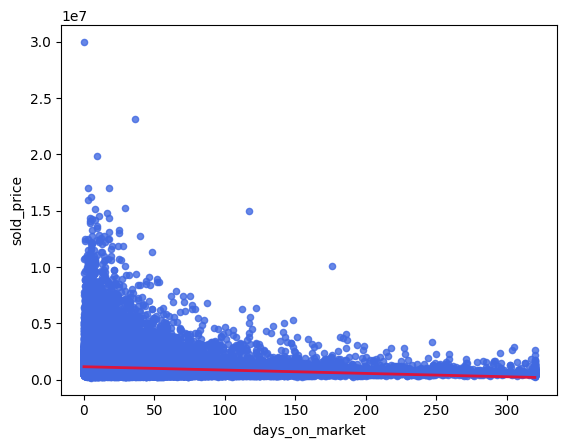

In [36]:
# listings.plot.scatter(y='sold_price', x='days_on_market')
sns.regplot(data=listings, x='days_on_market', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'}, # Style scatter dots
            line_kws={'color': 'crimson', 'lw': 2})    

<Axes: xlabel='days_on_market', ylabel='sold_price'>

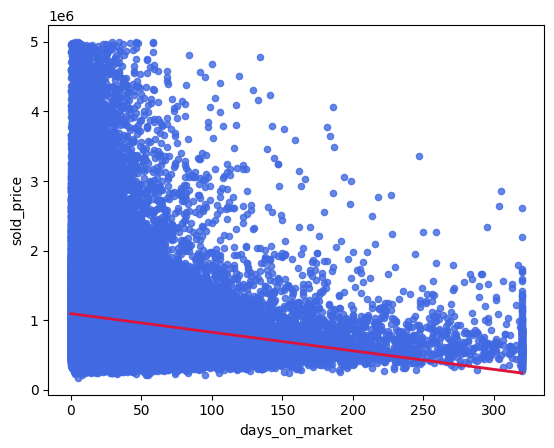

In [38]:
# listings[listings['sold_price'] < 0.5e7].plot.scatter(y='sold_price', x='days_on_market')
sns.regplot(data=listings[listings['sold_price'] < 0.5e7], 
            x='days_on_market', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'}, # Style scatter dots
            line_kws={'color': 'crimson', 'lw': 2})  

<Axes: xlabel='house_area', ylabel='sold_price'>

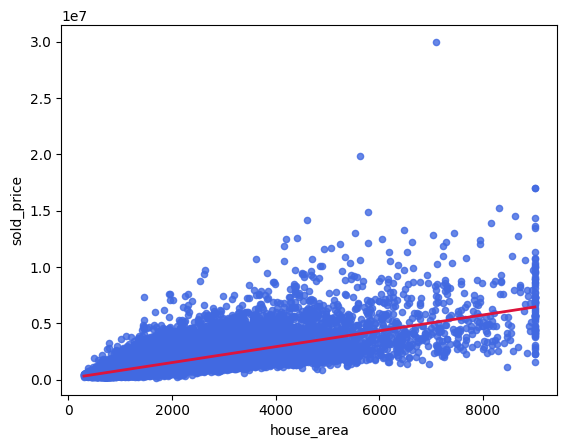

In [56]:
# listings.plot.scatter(y='sold_price', x='days_on_market')
df1 = listings.copy()
df1['house_area'] = pd.to_numeric(df1['house_area'], errors='coerce')
sns.regplot(data=df1, x='house_area', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'}, # Style scatter dots
            line_kws={'color': 'crimson', 'lw': 2})    

<Axes: xlabel='bedrooms', ylabel='sold_price'>

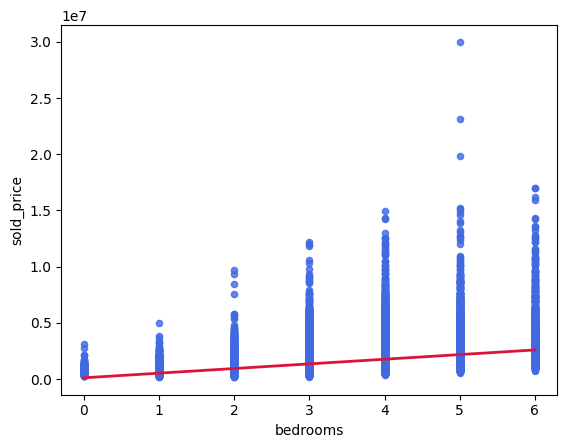

In [58]:
df1 = listings.copy()
df1['bedrooms'] = pd.to_numeric(df1['bedrooms'], errors='coerce')
sns.regplot(data=df1, x='bedrooms', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'}, # Style scatter dots
            line_kws={'color': 'crimson', 'lw': 2})  

<Axes: xlabel='washrooms', ylabel='sold_price'>

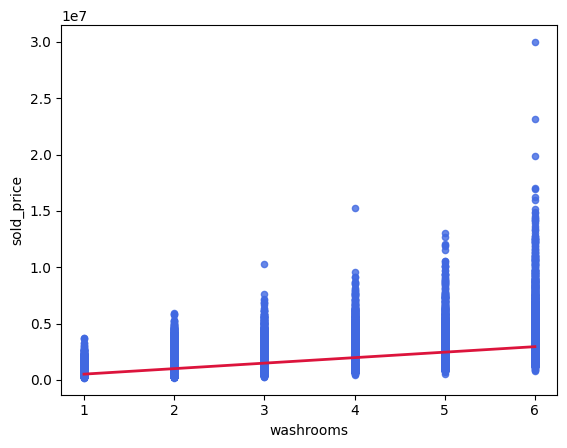

In [59]:
df1 = listings.copy()
df1['washrooms'] = pd.to_numeric(df1['washrooms'], errors='coerce')
sns.regplot(data=df1, x='washrooms', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'}, # Style scatter dots
            line_kws={'color': 'crimson', 'lw': 2})  

<Axes: xlabel='parking_total', ylabel='sold_price'>

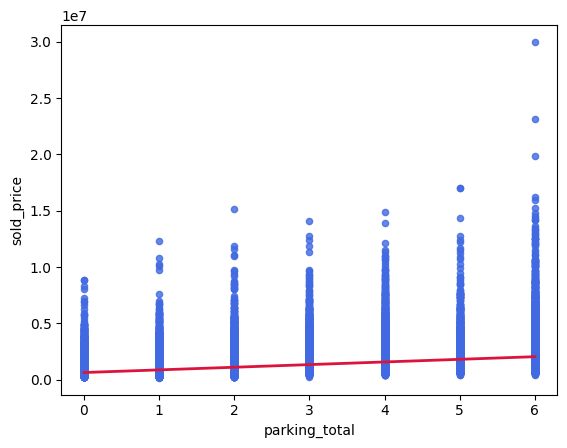

In [60]:
df1 = listings.copy()
df1['parking_total'] = pd.to_numeric(df1['parking_total'], errors='coerce')
sns.regplot(data=df1, x='parking_total', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'}, # Style scatter dots
            line_kws={'color': 'crimson', 'lw': 2})  

<Axes: xlabel='lot_front', ylabel='lot_depth'>

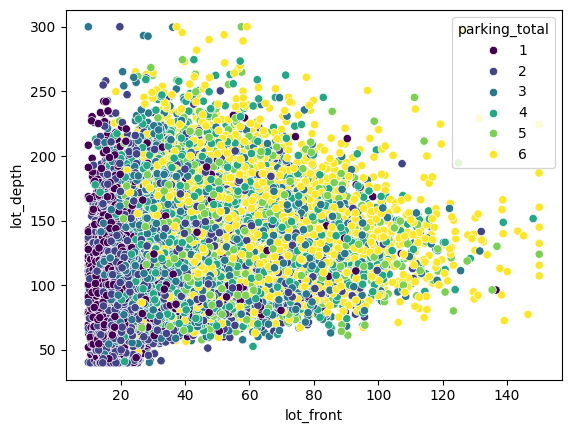

In [63]:
df1 = listings[listings['parking_total'] > 0]
sns.scatterplot(data=df1, x='lot_front', y='lot_depth', hue="parking_total", palette='viridis')

<Axes: xlabel='lot_area', ylabel='sold_price'>

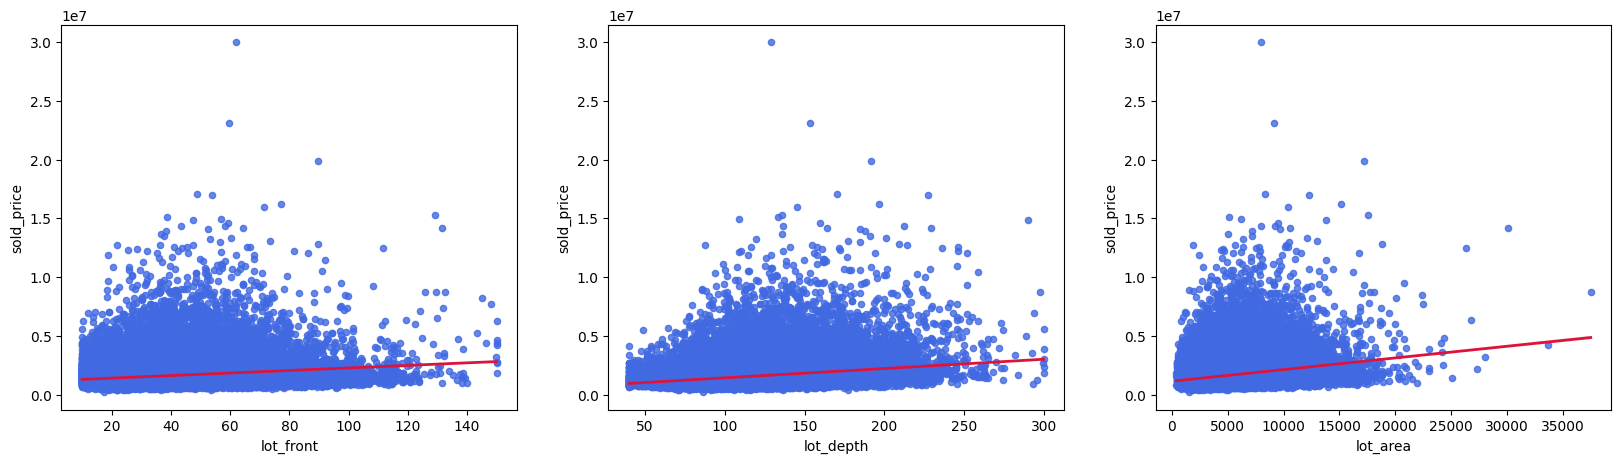

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

df1 = listings.copy()
df1['lot_area'] = df1['lot_front'] * df1['lot_depth'] 
sns.regplot(data=df1, x='lot_front', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'},
            line_kws={'color': 'crimson', 'lw': 2}, ax=axes[0])  

sns.regplot(data=df1, x='lot_depth', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'},
            line_kws={'color': 'crimson', 'lw': 2}, ax=axes[1])  

sns.regplot(data=df1, x='lot_area', y='sold_price', 
            scatter_kws={'s': 20, 'color': 'royalblue'},
            line_kws={'color': 'crimson', 'lw': 2}, ax=axes[2])

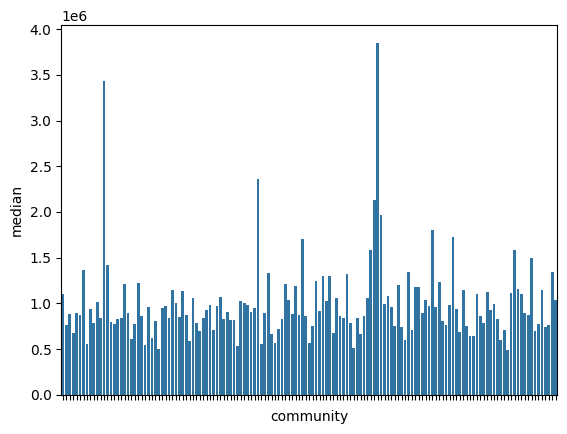

In [34]:
df2 = listings.groupby('community')["sold_price"].agg(['count', 'median', 'mean'])
ax = sns.barplot(data=df2, x='community', y='median')
ax.set_xticklabels([])
plt.show()

<Axes: xlabel='municipality', ylabel='mean'>

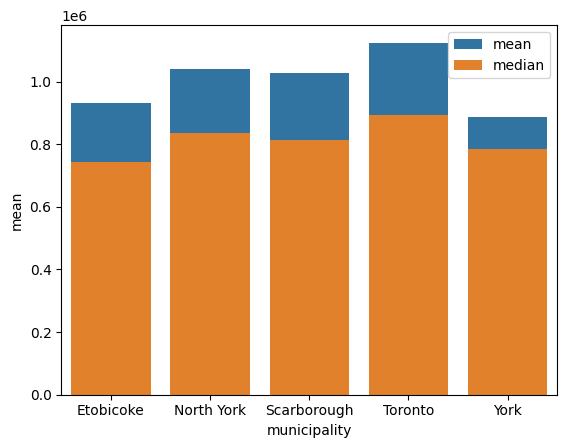

In [30]:
df3 = listings.groupby('municipality')["sold_price"].agg(['count', 'median', 'mean'])
sns.barplot(data=df3, x='municipality', y='mean', label='mean')
sns.barplot(data=df3, x='municipality', y='median', label='median')

<Axes: xlabel='longitude', ylabel='latitude'>

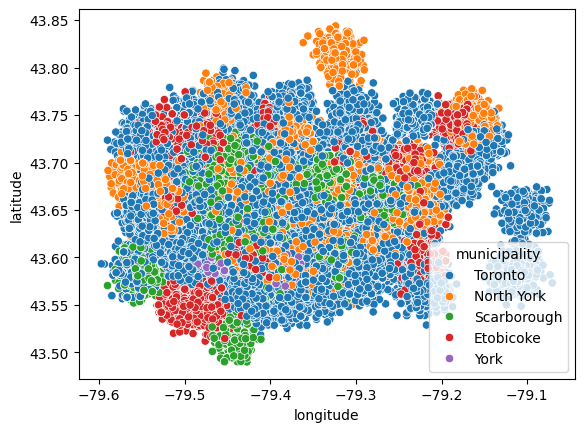

In [ ]:
sns.scatterplot(data=listings, x='longitude', y='latitude', hue='municipality')

<Axes: xlabel='sold_price', ylabel='price_diff'>

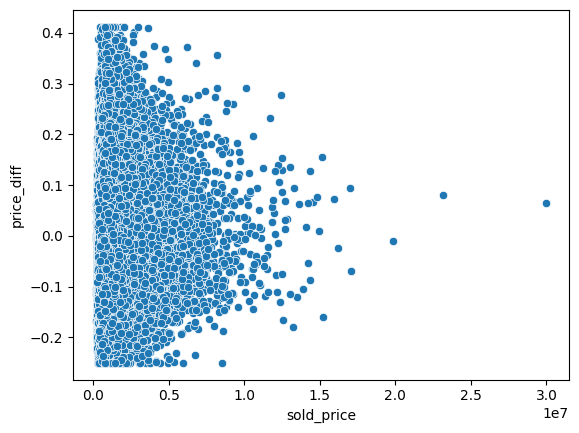

In [75]:
df4 = listings.copy()
df4['price_diff'] = (df4['sold_price'] - df4['list_price']) / df4['sold_price']
sns.scatterplot(data=df4, x='sold_price', y='price_diff')